# Nice Rooms: market, MARS and the rate call

Fourteen fictional hotels, 728 nights and a documented raise, hold or lower label. This notebook reads the JSON Lines panel, measures the market, and checks how far the stored call sits from the rule that produced it.


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})


def data_dir() -> Path:
    """The folder holding the JSON Lines files, on Kaggle or beside them."""
    for base in (
        Path("/kaggle/input/nice-rooms-hotel-revenue-rate-intelligence"),
        Path("."),
        Path("data/nice-rooms-kaggle"),
        Path("../data/nice-rooms-kaggle"),
    ):
        if (base / "hotels.jsonl").exists():
            return base
    found = list(Path("/kaggle/input").rglob("hotels.jsonl"))
    if found:
        return found[0].parent
    listing = sorted(str(path) for path in Path("/kaggle/input").rglob("*"))
    raise FileNotFoundError("hotels.jsonl not found; /kaggle/input holds " + repr(listing[:20]))


def load(name: str) -> pd.DataFrame:
    return pd.read_json(data_dir() / name, lines=True)


hotels = load("hotels.jsonl")
rooms = load("room_types.jsonl")
daily = load("daily_market.jsonl")
weekly = load("weekly_performance.jsonl")
decisions = load("rate_decisions.jsonl")
reviews = load("reviews.jsonl")
scenarios = load("review_scenarios.jsonl")

daily["date"] = pd.to_datetime(daily["date"])
weekly["week_start"] = pd.to_datetime(weekly["week_start"])
reviews["review_date"] = pd.to_datetime(reviews["review_date"])
reviews["stay_date"] = pd.to_datetime(reviews["stay_date"])
daily["month"] = daily["date"].dt.to_period("M").astype(str)
weekly["month"] = weekly["week_start"].dt.to_period("M").astype(str)


## The market at a glance

MARS moves with the peer group and with each hotel's positioning. The gap between the two lines is the space a revenue manager is paid to close.


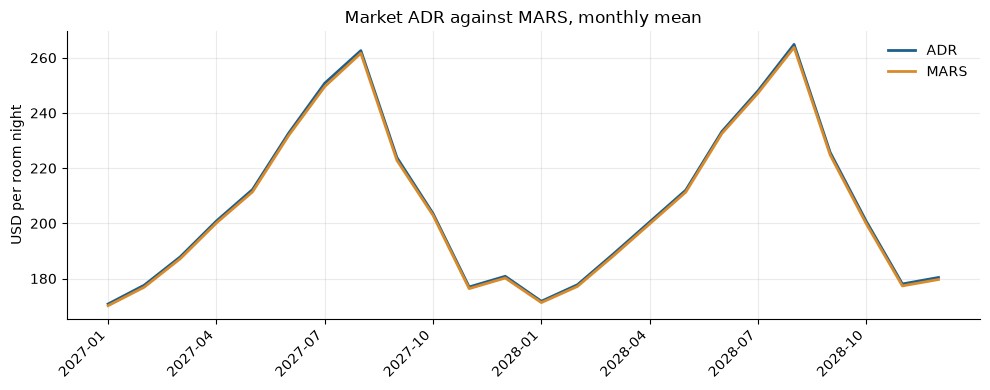

,adr,mars_rate
month,,
2028-07,248.00,247.18
2028-08,264.85,263.75
2028-09,225.70,224.77
2028-10,200.73,199.85
2028-11,178.04,177.34
2028-12,180.39,179.65


In [2]:
monthly = daily.groupby("month")[["adr", "mars_rate"]].mean().round(2)

ax = monthly.plot(color=["#1f5f8b", "#d98b2b"], linewidth=2)
ax.set_title("Market ADR against MARS, monthly mean")
ax.set_xlabel("")
ax.set_ylabel("USD per room night")
ax.legend(["ADR", "MARS"], frameon=False)
ax.set_xticks(range(0, len(monthly), 3))
ax.set_xticklabels(monthly.index[::3], rotation=45, ha="right")
plt.tight_layout()
plt.show()

monthly.tail(6)


## Where the calls sit

Raising calls cluster below MARS when the next week is already full. Lowering calls cluster above MARS, or on soft nights when pace is weak.


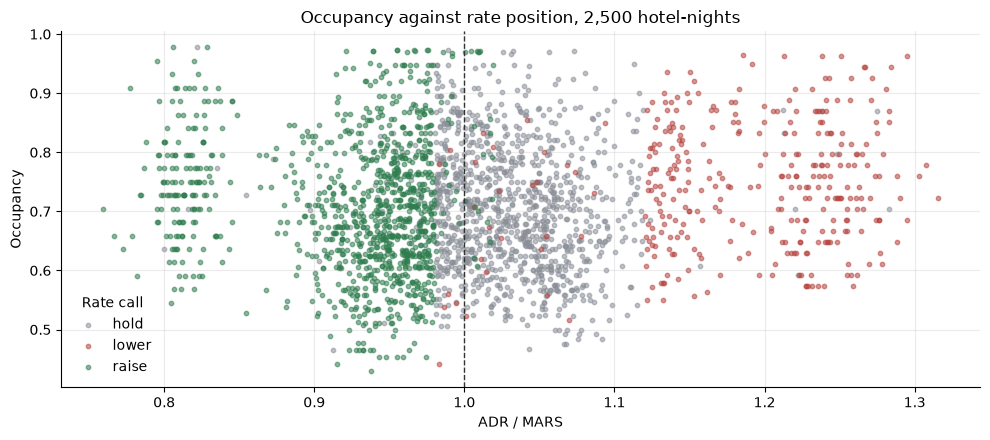

In [3]:
sample = daily.sample(2500, random_state=7)
colors = {"raise": "#2f7d4f", "hold": "#8a8f98", "lower": "#b5443f"}

ax = plt.figure(figsize=(10, 4.5)).add_subplot()
for action, group in sample.groupby("rate_action"):
    ax.scatter(group["rate_position"], group["occupancy"], s=10, alpha=0.55,
               label=action, color=colors[action])
ax.axvline(1.0, color="#333333", linewidth=1, linestyle="--")
ax.set_title("Occupancy against rate position, 2,500 hotel-nights")
ax.set_xlabel("ADR / MARS")
ax.set_ylabel("Occupancy")
ax.legend(frameon=False, title="Rate call")
plt.tight_layout()
plt.show()


## The call mix

Tier changes both the rate level and how often the hotel is out of position.


In [4]:
mix = (daily.groupby(["tier", "rate_action"]).size()
       .unstack(fill_value=0)
       .reindex(columns=["lower", "hold", "raise"]))
share = mix.div(mix.sum(axis=1), axis=0).round(3)
share


rate_action,lower,hold,raise
tier,,,
boutique,0.326,0.118,0.556
economy,0.023,0.504,0.473
luxury,0.018,0.564,0.418
midscale,0.018,0.601,0.381
upscale,0.169,0.432,0.399


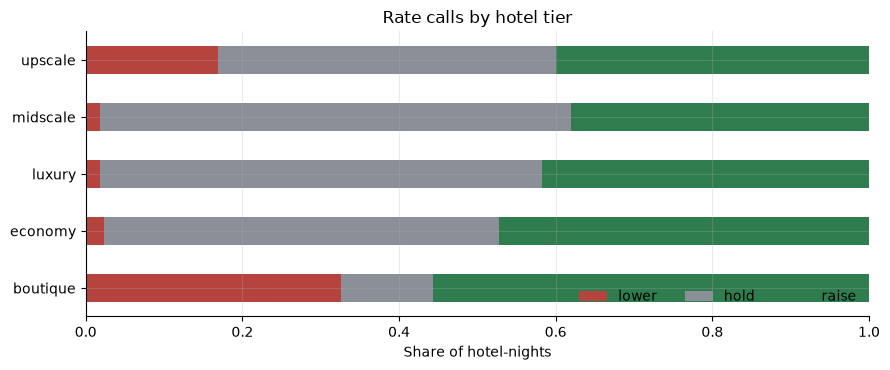

In [5]:
ax = share.plot(kind="barh", stacked=True, color=["#b5443f", "#8a8f98", "#2f7d4f"],
                figsize=(9, 3.8))
ax.set_title("Rate calls by hotel tier")
ax.set_xlabel("Share of hotel-nights")
ax.set_ylabel("")
ax.legend(["lower", "hold", "raise"], frameon=False, ncol=3, loc="lower right")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()


## Competitive indices and revenue

RGI, ARI and MPI place the hotel against its peer group. Total revenue is split by tier so the mix is visible over the two years.


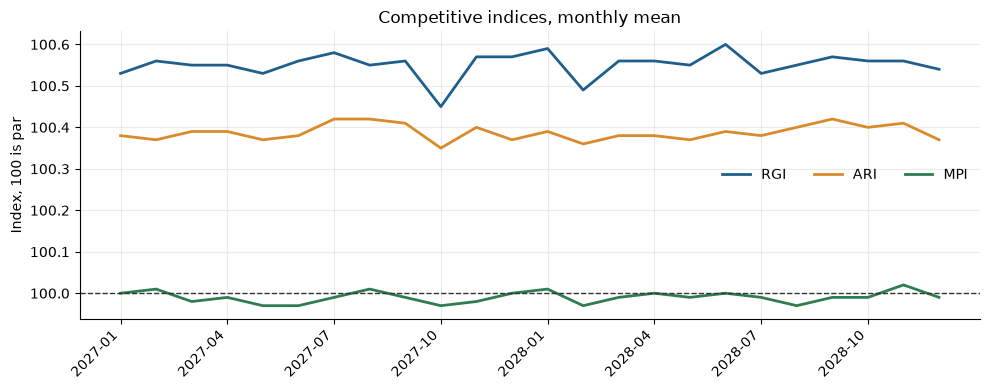

In [6]:
index = weekly.groupby("month")[["rgi", "ari", "mpi"]].mean().round(2)

ax = index.plot(linewidth=2, color=["#1f5f8b", "#d98b2b", "#2f7d4f"])
ax.axhline(100, color="#333333", linewidth=1, linestyle="--")
ax.set_title("Competitive indices, monthly mean")
ax.set_xlabel("")
ax.set_ylabel("Index, 100 is par")
ax.legend(["RGI", "ARI", "MPI"], frameon=False, ncol=3)
ax.set_xticks(range(0, len(index), 3))
ax.set_xticklabels(index.index[::3], rotation=45, ha="right")
plt.tight_layout()
plt.show()


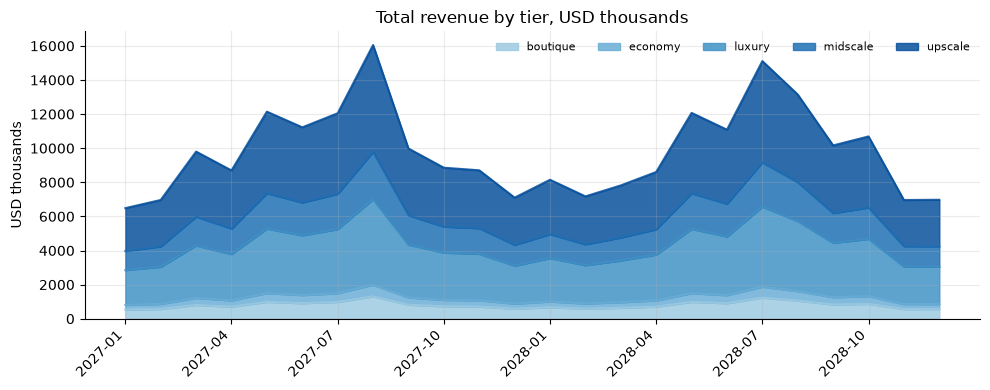

In [7]:
revenue = (weekly.pivot_table(index="month", columns="tier", values="total_revenue",
                             aggfunc="sum").fillna(0) / 1000)

ax = revenue.plot.area(figsize=(10, 4), alpha=0.85,
                       color=["#9ecae1", "#6baed6", "#4292c6", "#2171b5", "#08519c"])
ax.set_title("Total revenue by tier, USD thousands")
ax.set_xlabel("")
ax.set_ylabel("USD thousands")
ax.legend(frameon=False, ncol=5, fontsize=8)
ax.set_xticks(range(0, len(revenue), 3))
ax.set_xticklabels(revenue.index[::3], rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Is the label learnable?

The stored `rate_action` is a rule with three percent noise. Rebuilding the rule from the two observable signals shows the ceiling a classifier can reasonably aim for, and the confusion matrix shows where it breaks.


In [8]:
from itertools import product

daily["rule_call"] = "hold"
daily.loc[(daily["rate_position"] <= 0.98) & (daily["otb_occupancy_index"] >= 0.80), "rule_call"] = "raise"
daily.loc[(daily["rate_position"] <= 0.92) & (daily["otb_occupancy_index"] >= 0.72), "rule_call"] = "raise"
daily.loc[(daily["rate_position"] >= 1.12), "rule_call"] = "lower"
daily.loc[(daily["rate_position"] >= 1.06) & (daily["otb_occupancy_index"] <= 0.62), "rule_call"] = "lower"

agreement = (daily["rule_call"] == daily["rate_action"]).mean()
print("Agreement between the documented rule and the stored label:", round(agreement, 3))

confusion = pd.crosstab(daily["rate_action"], daily["rule_call"])
confusion


Agreement between the documented rule and the stored label: 0.958


rule_call,hold,lower,raise
rate_action,,,
hold,4199,39,145
lower,118,1185,0
raise,131,0,4375


## What happened after the call

The next week is attached to every decision, so the outcome can be scored. This is observational, not a causal lift: the counterfactual is not simulated.


In [9]:
decisions.groupby("action").agg(
    calls=("decision_id", "count"),
    mean_lift_pct=("realised_uplift_pct", "mean"),
    better_share=("outcome", lambda s: (s == "better").mean()),
).round(3)


,calls,mean_lift_pct,better_share
action,,,
hold,619,0.679,0.376
lower,189,0.601,0.429
raise,634,0.448,0.383


The panel is built so the rate call can be studied rather than guessed: MARS gives an
external benchmark, the rate position states the gap to it, and the on-the-books index states how
full the next week already looks. The stored label is a documented rule with three percent noise,
which makes it a fair target for a classifier and a fair baseline for a pricing policy.